# Phase 0 — Understanding HotpotQA

What a multi-hop question looks like, how its evidence is laid out, and what that implies
for retrieval over the shared corpus.

**Data used here.** Worked examples and example-level statistics come from the `eda` split
(1,500 training questions). Aggregates also come from `tune` (500 validation questions),
the only validation split examined in this notebook; its examples are not printed. The
blind splits (`test_retrieval`, `test_rag`, `test_agents`) are not loaded.

**Benchmark.** Every system searches one closed corpus built from the context paragraphs
of all 7,405 distractor-validation questions, rather than each question's own ten
paragraphs. Official answer and supporting-fact metrics are reused, but scores are not
comparable with the official distractor leaderboard.

In [1]:
import collections
import textwrap

import bm25s
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import Stemmer

import data

BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, MUTED = "#0b0b0b", "#52514e"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6})

corpus = data.corpus()
print("corpus fingerprint verified:", data.verify_corpus()[:16], "...")
eda = data.load_split("eda")
tune = data.load_split("tune")
print(f"eda: {len(eda)} train questions; tune: {len(tune)} validation questions; corpus: {len(corpus):,} paragraphs")

corpus fingerprint verified: 67db29c2a555974d ...


eda: 1500 train questions; tune: 500 validation questions; corpus: 66,635 paragraphs


## 1. Question and answer mix

Two question types. **Bridge** questions reach the answer through an intermediate entity
that the question does not name. **Comparison** questions name two entities and ask which
one has a property, or whether both share one; many of these are yes/no.

In [2]:
from metrics import normalize_answer as data_norm


def answer_kind(a):
    return "yes/no" if data_norm(a) in ("yes", "no") else "span"


def mix(questions, name):
    df = pd.DataFrame({"type": [q.type for q in questions], "level": [q.level for q in questions],
                       "kind": [answer_kind(q.answer) for q in questions],
                       "answer_words": [len(q.answer.split()) for q in questions]})
    rows = {}
    for ty, g in df.groupby("type"):
        rows[ty] = {"questions": len(g), "share": len(g) / len(df), "yes/no answers": (g.kind == "yes/no").mean(),
                    "median answer words (spans)": g.loc[g.kind == "span", "answer_words"].median()}
    out = pd.DataFrame(rows).T
    out.index = pd.MultiIndex.from_product([[name], out.index])
    return out, df

m_eda, df_eda = mix(eda, "eda (train)")
m_tune, df_tune = mix(tune, "tune (validation)")
display(pd.concat([m_eda, m_tune]).round(3))
print("levels in eda:", df_eda.level.value_counts().to_dict(), "| levels in tune:", df_tune.level.value_counts().to_dict())

questions  share  yes/no answers  \
eda (train)       bridge         1211.0  0.807           0.000   
                  comparison      289.0  0.193           0.322   
tune (validation) bridge          400.0  0.800           0.000   
                  comparison      100.0  0.200           0.300   

                              median answer words (spans)  
eda (train)       bridge                              2.0  
                  comparison                          2.0  
tune (validation) bridge                              2.0  
                  comparison                          2.0

levels in eda: {'medium': 960, 'easy': 285, 'hard': 255} | levels in tune: {'hard': 500}


## 2. Evidence chains, worked through

Each question has exactly two gold paragraphs and a list of supporting sentences. For a
bridge question, one gold paragraph (the **first hop**) mentions the entity that the other
gold paragraph (the **second hop**) is about. The helper below orders the hops by that
link: the paragraph whose supporting sentences mention the other paragraph's title comes
first.

The examples are chosen by a fixed rule, not by hand: in the `eda` split's seeded order,
the first two bridge questions, the first comparison question with a span answer, and the
first with a yes/no answer.

In [3]:
eda_ctx = data.load_contexts("eda")


def mentions(text, title):
    """Does ``text`` mention ``title``? Case-insensitive; a trailing disambiguator such as
    "(1926 film)" is dropped from the title first."""
    core = title.split(" (")[0].lower()
    return core in text.lower()


def contains_answer(answer, text):
    """Whole-token containment of the normalised answer; undefined for yes/no answers."""
    a, t = data_norm(answer).split(), data_norm(text).split()
    return any(t[i:i + len(a)] == a for i in range(len(t) - len(a) + 1)) if a else False


def chain(q, ctx):
    """Hop order, supporting sentences and answer location for one question.

    Bridge hop order, first rule that applies: (1) the paragraph whose supporting sentences
    name the other's title is hop 1; (2) the same over the full paragraph text; (3) the
    paragraph whose title the question names is hop 1; (4) the paragraph containing the
    answer is hop 2. ``rule`` records which one decided."""
    paras = ctx[q.qid]
    titles = [t for t, _ in q.gold]
    sup = {t: [(i, paras[t][i].strip()) for tt, i in q.supporting_facts if tt == t and i < len(paras[t])]
           for t in titles}
    sup_text = {t: " ".join(s for _, s in sup[t]) for t in titles}
    full = {t: " ".join(paras[t]) for t in titles}
    named = {t: mentions(q.question, t) for t in titles}
    yes_no = answer_kind(q.answer) == "yes/no"
    has_ans = {t: (not yes_no) and contains_answer(q.answer, full[t]) for t in titles}
    a, b = titles
    rule = None
    if q.type == "bridge":
        for rule, first in (("supporting", lambda x, y: mentions(sup_text[x], y)),
                            ("paragraph", lambda x, y: mentions(full[x], y)),
                            ("question", lambda x, y: named[x]),
                            ("answer", lambda x, y: has_ans[y])):
            fa, fb = first(a, b), first(b, a)
            if fa != fb:
                if fb:
                    a, b = b, a
                break
        else:
            rule = "undetermined"
    return {"order": [a, b], "sup": sup, "rule": rule, "in_question": named,
            "answer_in": [t for t in (a, b) if has_ans[t]], "yes_no": yes_no}


def show(q):
    c = chain(q, eda_ctx)
    print(f"[{q.type}, {q.level}] {q.question}\n  answer: {q.answer}")
    for hop, t in enumerate(c["order"], 1):
        label = f"hop {hop}" if q.type == "bridge" else f"entity {hop}"
        print(f"  {label}: «{t}»  (title named in question: {'yes' if c['in_question'][t] else 'no'})")
        for i, s in c["sup"][t]:
            print(textwrap.fill(f"s{i}: {s}", 100, initial_indent="      ", subsequent_indent="          "))
    if q.type == "bridge":
        print(f"  hop order decided by: {c['rule']}")
    where = "yes/no answer" if c["yes_no"] else (c["answer_in"] or "neither paragraph (paraphrased)")
    print(f"  answer found in: {where}\n")


bridge = [q for q in eda if q.type == "bridge"]
comp = [q for q in eda if q.type == "comparison"]
examples = bridge[:2] + [next(q for q in comp if answer_kind(q.answer) == "span"),
                         next(q for q in comp if answer_kind(q.answer) == "yes/no")]
for q in examples:
    show(q)

[bridge, medium] What year was the sports star who guest starred in the episode "Promos" in the television show "The Office" born?
  answer: 1975
  hop 1: «Promos (The Office)»  (title named in question: yes)
      s0: "Promos" is the eighteenth episode of the ninth season of the American comedy television
          series "The Office" and the 193rd overall.
  hop 2: «Chris Diamantopoulos»  (title named in question: no)
      s0: Christopher "Chris" Diamantopoulos (born May 9, 1975; Greek: Χριστόφορος "Κρις"
          Διαμαντόπουλος ) is a Greek-Canadian actor and comedian.
  hop order decided by: paragraph
  answer found in: ['Chris Diamantopoulos']

[bridge, medium] When was the director of the 1991 film Naked Lunch born?
  answer: March 15, 1943
  hop 1: «Naked Lunch (film)»  (title named in question: yes)
      s0: Naked Lunch is a 1991 science fiction drama film co-written and directed by David
          Cronenberg and starring Peter Weller, Judy Davis, Ian Holm, and Roy Scheider.

The four chains, read as retrieval problems:

1. **Promos → Chris Diamantopoulos (bridge).** The question names only the episode. The
   actor's paragraph is reachable only through the episode paragraph, and only through a
   sentence (s3, "The episode guest stars sports star Ryan Howard, Chris Diamantopoulos,
   …") that is *not* marked as supporting. The label is also doubtful: the "sports star"
   in s3 is Ryan Howard, while the gold answer is Diamantopoulos's birth year. HotpotQA
   has annotation noise, and part of any system's error will be label error.
2. **Naked Lunch → David Cronenberg (bridge).** A clean two-hop chain: the film paragraph
   names the director, and the director's paragraph holds the answer. A query for the
   second hop needs "David Cronenberg", which appears only in the first-hop evidence. That
   is exactly the case where a second, evidence-dependent search can help. The paragraph
   also carries debris from Wikipedia templates (`{'1': ", '2': ", …}`) inside a sentence.
3. **Innocence / The Importance of Being Icelandic (comparison).** Both entities are named,
   so one query can plausibly retrieve both paragraphs. The answer is a shared property,
   not an entity.
4. **Chippewa Valley / Yeager airports (comparison, yes/no).** Both are named again. The
   answer "no" appears in neither paragraph: it is inferred by comparing "Wisconsin" with
   "West Virginia", so the answer cannot be checked by string matching.

## 3. How often the second hop is hidden from the question

The same measurements over whole splits: whether each gold title is named in the question,
where the answer sits, and which rule fixed the bridge hop order. Title matching drops a
trailing disambiguator ("(1926 film)") and is case-insensitive; it is a lower bound on
"named", since paraphrases ("the 1991 film" for *Naked Lunch*) are not detected.

In [4]:
tune_ctx = data.load_contexts("tune")


def chain_table(questions, ctx, name):
    rows = []
    for q in questions:
        c = chain(q, ctx)
        first, second = c["order"]
        rows.append({"split": name, "type": q.type, "rule": c["rule"], "yes_no": c["yes_no"],
                     "hop1_named": c["in_question"][first], "hop2_named": c["in_question"][second],
                     "answer_in_hop2": second in c["answer_in"], "answer_in_hop1": first in c["answer_in"],
                     "answer_in_neither": not c["answer_in"] and not c["yes_no"]})
    return pd.DataFrame(rows)


chains = pd.concat([chain_table(eda, eda_ctx, "eda"), chain_table(tune, tune_ctx, "tune")])
cols = ["hop1_named", "hop2_named", "answer_in_hop1", "answer_in_hop2", "answer_in_neither"]
summary = chains.groupby(["split", "type"])[cols].mean().round(3)
summary.insert(0, "n", chains.groupby(["split", "type"]).size())
display(summary)
print("bridge hop order decided by (share):")
display(chains[chains.type == "bridge"].groupby("split")["rule"].value_counts(normalize=True).unstack().round(3))

n  hop1_named  hop2_named  answer_in_hop1  \
split type                                                       
eda   bridge      1211       0.673        0.14           0.459   
      comparison   289       1.000        1.00           0.443   
tune  bridge       400       0.650        0.08           0.385   
      comparison   100       1.000        1.00           0.350   

                  answer_in_hop2  answer_in_neither  
split type                                           
eda   bridge               0.829              0.004  
      comparison           0.408              0.003  
tune  bridge               0.820              0.008  
      comparison           0.500              0.000

bridge hop order decided by (share):


rule,answer,paragraph,question,supporting,undetermined
split,,,,,
eda,0.052,0.088,0.079,0.765,0.017
tune,0.065,0.080,0.072,0.762,0.020


## 4. Word overlap between the question and its evidence

A first look at what lexical retrieval can reach. Overlap is the share of the question's
tokens that also occur in a paragraph's indexed text (`title. text`), using the tokenizer
the BM25 baseline will use: `bm25s` with English stop words removed and Snowball
stemming. It is a proxy for BM25 scoring, not BM25 itself: no term weighting, no length
normalisation.

The control is each question's own eight distractors. HotpotQA picked them for their
TF-IDF similarity to that question, so they are a hard, like-for-like comparison. The
last column counts how many of the eight have *strictly higher* overlap than the gold
paragraph: a paragraph outranked by distractors on overlap will struggle to reach a small
top-K.

In [5]:
stemmer = Stemmer.Stemmer("english")


def tokens(texts):
    return [set(t) for t in bm25s.tokenize(texts, stopwords="en", stemmer=stemmer,
                                           return_ids=False, show_progress=False)]


def overlap_table(questions, ctx, name):
    rows = []
    for q in questions:
        c = chain(q, ctx)
        titles = list(ctx[q.qid])
        texts = [f"{t}. {''.join(ctx[q.qid][t]).strip()}" for t in titles]
        qt, *pt = tokens([q.question] + texts)
        ov = {t: len(qt & p) / len(qt) if qt else 0.0 for t, p in zip(titles, pt)}
        distract = [ov[t] for t in titles if t not in c["order"]]
        for hop, t in enumerate(c["order"], 1):
            rows.append({"split": name, "type": q.type, "paragraph": f"hop {hop}" if q.type == "bridge" else "entity",
                         "overlap": ov[t], "distractor_mean": float(np.mean(distract)) if distract else np.nan,
                         "distractors_above": sum(d > ov[t] for d in distract), "n_distractors": len(distract)})
    return pd.DataFrame(rows)


ov = pd.concat([overlap_table(eda, eda_ctx, "eda"), overlap_table(tune, tune_ctx, "tune")])
tab = ov.groupby(["split", "type", "paragraph"]).agg(
    overlap=("overlap", "mean"), distractor_overlap=("distractor_mean", "mean"),
    zero_overlap=("overlap", lambda s: (s == 0).mean()),
    outranked_by_3plus=("distractors_above", lambda s: (s >= 3).mean()),
    mean_distractors_above=("distractors_above", "mean")).round(3)
display(tab)
short = {name: sum(len(ctx[q.qid]) < 10 for q in qs) for name, qs, ctx in (("eda", eda, eda_ctx), ("tune", tune, tune_ctx))}
print("questions with fewer than ten paragraphs (fewer than 8 distractors):", short)

overlap  distractor_overlap  zero_overlap  \
split type       paragraph                                              
eda   bridge     hop 1        0.530               0.384         0.001   
                 hop 2        0.444               0.384         0.019   
      comparison entity       0.407               0.380         0.000   
tune  bridge     hop 1        0.507               0.383         0.000   
                 hop 2        0.438               0.383         0.012   
      comparison entity       0.418               0.379         0.000   

                            outranked_by_3plus  mean_distractors_above  
split type       paragraph                                              
eda   bridge     hop 1                   0.186                   1.250  
                 hop 2                   0.333                   2.319  
      comparison entity                  0.287                   1.872  
tune  bridge     hop 1                   0.205                   1.495  
                 hop 2                   0.355                   2.372  
      comparison entity                  0.250                   1.760

questions with fewer than ten paragraphs (fewer than 8 distractors): {'eda': 15, 'tune': 5}


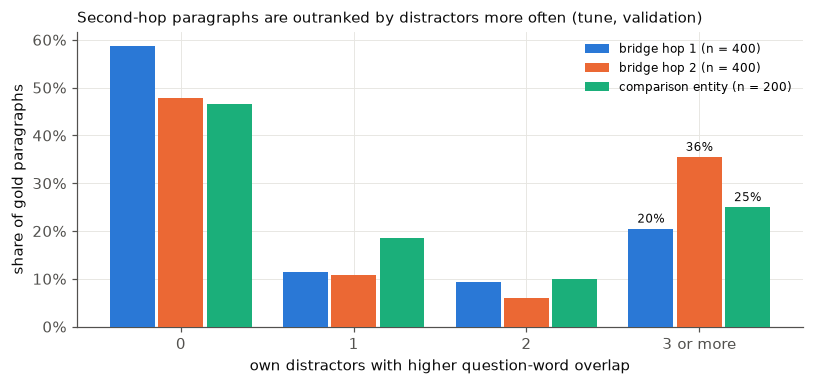

In [6]:
AQUA = "#1baf7a"
t = ov[ov.split == "tune"].copy()
t["role"] = np.where(t.type == "comparison", "comparison entity", "bridge " + t.paragraph)
t["above"] = pd.cut(t.distractors_above, [-1, 0, 1, 2, 99], labels=["0", "1", "2", "3+"])
share = t.groupby("role", observed=False)["above"].value_counts(normalize=True).unstack()
counts = t.groupby("role").size()

fig, ax = plt.subplots(figsize=(7.5, 3.6))
x = np.arange(4)
width = 0.26
for i, (role, color) in enumerate([("bridge hop 1", BLUE), ("bridge hop 2", ORANGE), ("comparison entity", AQUA)]):
    vals = share.loc[role, ["0", "1", "2", "3+"]].to_numpy()
    bars = ax.bar(x + (i - 1) * (width + 0.02), vals, width, color=color, label=f"{role} (n = {counts[role]})", zorder=3)
    ax.bar_label(bars, labels=[f"{v:.0%}" if j == 3 else "" for j, v in enumerate(vals)], padding=2, fontsize=8, color=INK)
ax.set_xticks(x, ["0", "1", "2", "3 or more"])
ax.set_xlabel("own distractors with higher question-word overlap")
ax.set_ylabel("share of gold paragraphs")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0))
ax.set_title("Second-hop paragraphs are outranked by distractors more often (tune, validation)", fontsize=10, color=INK, loc="left")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

## 5. The corpus as the LLM will see it

Paragraph length decides how many paragraphs fit in the 8,192-token context, and
therefore the ceiling on K and on the agents' accumulated context. Each paragraph is
rendered as it will appear in prompts: a title line, then one numbered line per sentence.
Lengths are counted with the pinned Qwen2.5 tokenizer. These statistics use corpus text
only, with no labels.

In [7]:
import re

import llm

count = llm.qwen_token_counter()


def render(doc):
    return f"## {doc.title}\n" + "\n".join(f"[{i}] {s.strip()}" for i, s in enumerate(doc.sentences))


docs = list(corpus.values())
n_tok = np.array([count(render(d)) for d in docs])
n_sent = np.array([len(d.sentences) for d in docs])
debris = re.compile(r"\{'\d+': ")
has_debris = np.array([bool(debris.search(d.text)) for d in docs])
empty = np.array([not d.text for d in docs])

print(f"paragraphs: {len(docs):,}")
print(f"tokens per rendered paragraph: median {np.median(n_tok):.0f}, mean {n_tok.mean():.0f}, "
      f"p95 {np.percentile(n_tok, 95):.0f}, max {n_tok.max():,}")
print(f"sentences per paragraph: median {np.median(n_sent):.0f}, p95 {np.percentile(n_sent, 95):.0f}, max {n_sent.max()}")
print(f"paragraphs with template debris {{'1': ...}}: {has_debris.sum():,} ({has_debris.mean():.1%}); empty paragraphs: {empty.sum()}")
budget = 8192 - 512 - 400   # num_ctx - num_predict - instructions and question (allowance)
for k in (5, 10, 15, 20):
    print(f"K = {k:2d}: mean-length context {k * n_tok.mean():5.0f} tokens; "
          f"p95-length context {k * np.percentile(n_tok, 95):5.0f} (budget ≈ {budget})")

paragraphs: 66,635
tokens per rendered paragraph: median 133, mean 147, p95 288, max 2,321
sentences per paragraph: median 4, p95 8, max 85
paragraphs with template debris {'1': ...}: 215 (0.3%); empty paragraphs: 0
K =  5: mean-length context   736 tokens; p95-length context  1440 (budget ≈ 7280)
K = 10: mean-length context  1471 tokens; p95-length context  2880 (budget ≈ 7280)
K = 15: mean-length context  2207 tokens; p95-length context  4320 (budget ≈ 7280)
K = 20: mean-length context  2943 tokens; p95-length context  5760 (budget ≈ 7280)


## 6. What this means for the systems

- **Multi-hop is mostly a bridge problem.** 80% of questions are bridge questions, and
  their second-hop paragraph is almost never named in the question (8% on `tune`, 14% on
  `eda`). It shares fewer question words than the first hop (0.44 against 0.51 on
  `tune`) and is outranked by three or more of its own distractors in 36% of questions,
  against 20% for the first hop. A single retrieval pass with the question is therefore
  expected to find the first hop more reliably than the second. The name that unlocks the
  second hop typically appears only in the first hop's text, as with *Naked Lunch* →
  *David Cronenberg*.
- **Comparison questions name both entities** in every case measured, so one query
  carries both targets. They still compete with similar distractors: 25% of their gold
  paragraphs are outranked by three or more.
- **The answer usually sits in the second hop** (82% of bridge questions on `tune`). About
  30% of comparison answers are yes/no and appear in neither paragraph, so they cannot be
  checked by string matching; only the answer metrics and the cited evidence can.
- **Labels are noisy.** In the first worked example the linking sentence is not marked as
  supporting, and the gold answer does not match the question's "sports star". Some
  measured error will be label error; failure analysis should record it as a category.
- **Text is mostly clean.** 0.3% of paragraphs contain template debris; none are empty.
- **Context budget.** Rendered paragraphs have a median of 133 tokens (p95 288). Twenty
  paragraphs of p95 length fit within the 8,192-token context with room for instructions.
  The longest paragraph has 2,321 tokens, so an oversized context is possible but rare; a
  rule for that case is needed before the first LLM run.
- **Validation is harder than train.** `tune` is all `hard`, while `eda` mixes easy,
  medium and hard; the chain statistics differ only slightly between them (for example,
  second-hop titles named in 8% against 14%).